# Dimensionality Reduction & Unsupervised Clustering

This notebook applies standardization, PCA, K-Means, DBSCAN, and Agglomerative (hierarchical) clustering to the ten numerical features in scikit-learn's Diabetes dataset.

**Goal:** explore patterns in high-dimensional numerical data. The dataset target is not used for PCA or clustering, so this remains an unsupervised analysis.

## Workflow
1. Standardize numerical features.
2. Inspect PCA explained variance with scree and cumulative-variance plots.
3. Select a candidate number of K-Means clusters using elbow and silhouette analysis.
4. Fit K-Means, DBSCAN, and hierarchical clustering.
5. Visualize clusters in the first two principal components and compare metrics.

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_diabetes
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
data = load_diabetes(as_frame=True)
X = data.data.copy()
print("Rows:", X.shape[0], "| Features:", X.shape[1])
display(X.head())
print("Missing values:", int(X.isna().sum().sum()))

Rows: 442 | Features: 10


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


Missing values: 0


## 1. Standardize features

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Feature means after scaling (approximately 0):", np.round(X_scaled.mean(axis=0), 3))
print("Feature standard deviations:", np.round(X_scaled.std(axis=0), 3))

Feature means after scaling (approximately 0): [ 0.  0. -0. -0. -0.  0.  0.  0. -0. -0.]
Feature standard deviations: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 2. Principal Component Analysis (PCA)

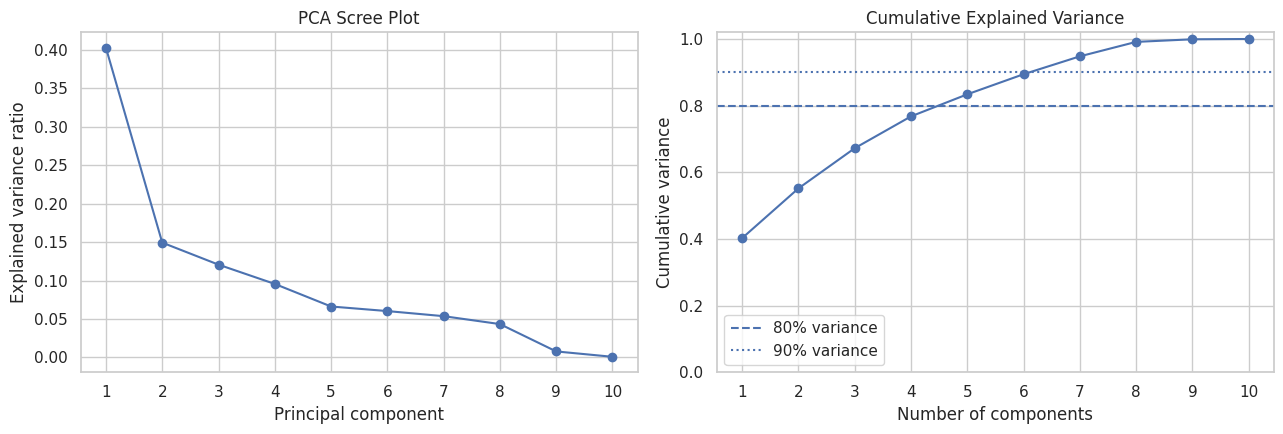

,PC,explained_variance_ratio,cumulative_variance
0,PC1,0.4024,0.4024
1,PC2,0.1492,0.5517
2,PC3,0.1206,0.6722
3,PC4,0.0955,0.7678
4,PC5,0.0662,0.8340
5,PC6,0.0603,0.8943
6,PC7,0.0537,0.9479
7,PC8,0.0434,0.9913
8,PC9,0.0078,0.9991
9,PC10,0.0009,1.0000


Components for >=80% variance: 5; for >=90% variance: 7


In [ ]:
pca = PCA()
X_pca = pca.fit_transform(X_scaled)
var = pca.explained_variance_ratio_
cumvar = np.cumsum(var)
pcs = np.arange(1, len(var) + 1)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(pcs, var, marker="o")
ax[0].set(title="PCA Scree Plot", xlabel="Principal component", ylabel="Explained variance ratio")
ax[0].set_xticks(pcs)
ax[1].plot(pcs, cumvar, marker="o")
ax[1].axhline(.80, linestyle="--", label="80% variance")
ax[1].axhline(.90, linestyle=":", label="90% variance")
ax[1].set(title="Cumulative Explained Variance", xlabel="Number of components", ylabel="Cumulative variance")
ax[1].set_ylim(0, 1.02); ax[1].set_xticks(pcs); ax[1].legend()
plt.tight_layout(); plt.show()

variance_table = pd.DataFrame({"PC": [f"PC{i}" for i in pcs],
                               "explained_variance_ratio": var,
                               "cumulative_variance": cumvar})
display(variance_table.round(4))
n80 = int(np.argmax(cumvar >= .80) + 1)
n90 = int(np.argmax(cumvar >= .90) + 1)
print(f"Components for >=80% variance: {n80}; for >=90% variance: {n90}")

**Interpretation:** the scree plot shows each component's contribution; cumulative variance shows how many components are needed to retain a chosen proportion of variance. The threshold is a practical guide, not a universal rule.

## 3. K-Means: elbow and silhouette analysis

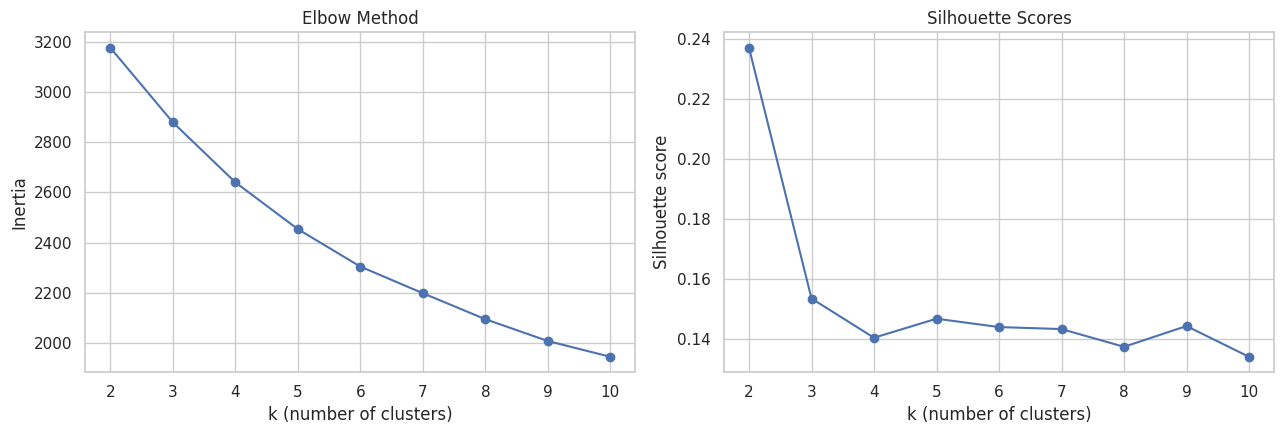

,k,inertia,silhouette_score
0,2,3176.6549,0.2370
1,3,2879.2112,0.1535
2,4,2639.9737,0.1404
3,5,2453.2386,0.1467
4,6,2303.9354,0.1440
5,7,2197.6708,0.1433
6,8,2094.1680,0.1374
7,9,2006.9935,0.1443
8,10,1944.1683,0.1341


Highest silhouette score among tested k values: 2


In [ ]:
ks = list(range(2, 11))
inertias, silhouettes = [], []
for k in ks:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    labels = model.fit_predict(X_scaled)
    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(ks, inertias, marker="o")
ax[0].set(title="Elbow Method", xlabel="k (number of clusters)", ylabel="Inertia")
ax[1].plot(ks, silhouettes, marker="o")
ax[1].set(title="Silhouette Scores", xlabel="k (number of clusters)", ylabel="Silhouette score")
plt.tight_layout(); plt.show()

k_table = pd.DataFrame({"k": ks, "inertia": inertias, "silhouette_score": silhouettes})
display(k_table.round(4))
best_k = int(k_table.loc[k_table.silhouette_score.idxmax(), "k"])
print("Highest silhouette score among tested k values:", best_k)

## 4. K-Means clusters in 2D PCA projection

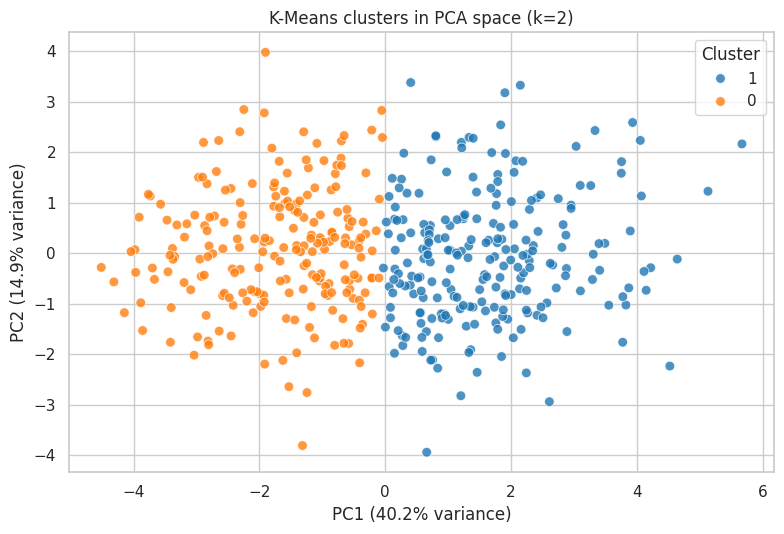

K-Means silhouette in full standardized feature space: 0.237


,cluster_size
0,214
1,228


In [ ]:
kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=20)
labels_kmeans = kmeans.fit_predict(X_scaled)
pca2 = PCA(n_components=2)
X_2d = pca2.fit_transform(X_scaled)
viz = pd.DataFrame({"PC1": X_2d[:, 0], "PC2": X_2d[:, 1],
                    "Cluster": labels_kmeans.astype(str)})
plt.figure(figsize=(8, 5.5))
sns.scatterplot(data=viz, x="PC1", y="PC2", hue="Cluster", palette="tab10", s=48, alpha=.8)
plt.title(f"K-Means clusters in PCA space (k={best_k})")
plt.xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.tight_layout(); plt.show()
print("K-Means silhouette in full standardized feature space:", round(silhouette_score(X_scaled, labels_kmeans), 4))
display(pd.Series(labels_kmeans).value_counts().sort_index().rename("cluster_size").to_frame())

## 5. DBSCAN

DBSCAN identifies dense regions and marks low-density observations as noise (`-1`). It does not require choosing a cluster count, but its results are sensitive to `eps` and `min_samples`. We test several `eps` values on standardized features.

,eps,min_samples,clusters_excluding_noise,noise_fraction,silhouette_non_noise_only
0,1.5,8,5,0.7172,0.2597
1,2.0,8,2,0.1787,0.1788
2,2.5,8,1,0.0294,NaN
3,3.0,8,1,0.0023,NaN
4,3.5,8,1,0.0000,NaN


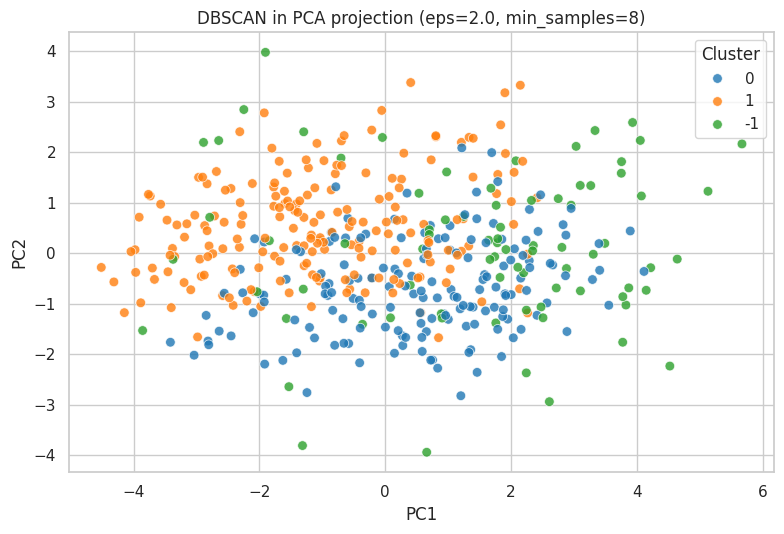

Selected eps: 2.0 | noise points: 79 of 442
Labels include -1 for noise: True


In [ ]:
eps_values = [1.5, 2.0, 2.5, 3.0, 3.5]
min_samples = 8
db_rows, db_labels = [], {}
for eps in eps_values:
    labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)
    db_labels[eps] = labels
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    noise = float(np.mean(labels == -1))
    keep = labels != -1
    if n_clusters >= 2 and keep.sum() > n_clusters:
        sil = silhouette_score(X_scaled[keep], labels[keep])
    else:
        sil = np.nan
    db_rows.append({"eps": eps, "min_samples": min_samples, "clusters_excluding_noise": n_clusters,
                    "noise_fraction": noise, "silhouette_non_noise_only": sil})
db_table = pd.DataFrame(db_rows)
display(db_table.round(4))

valid = db_table[db_table.clusters_excluding_noise >= 2]
if len(valid):
    chosen = valid.sort_values(["noise_fraction", "silhouette_non_noise_only"],
                               ascending=[True, False], na_position="last").iloc[0]
else:
    chosen = db_table.sort_values(["clusters_excluding_noise", "noise_fraction"],
                                  ascending=[False, True]).iloc[0]
chosen_eps = float(chosen.eps)
labels_db = db_labels[chosen_eps]
db_viz = pd.DataFrame({"PC1": X_2d[:, 0], "PC2": X_2d[:, 1], "Cluster": labels_db.astype(str)})
plt.figure(figsize=(8, 5.5))
sns.scatterplot(data=db_viz, x="PC1", y="PC2", hue="Cluster", palette="tab10", s=48, alpha=.8)
plt.title(f"DBSCAN in PCA projection (eps={chosen_eps}, min_samples={min_samples})")
plt.tight_layout(); plt.show()
print("Selected eps:", chosen_eps, "| noise points:", int(np.sum(labels_db == -1)), "of", len(labels_db))
print("Labels include -1 for noise:", -1 in set(labels_db))

## 6. Hierarchical (Agglomerative) clustering

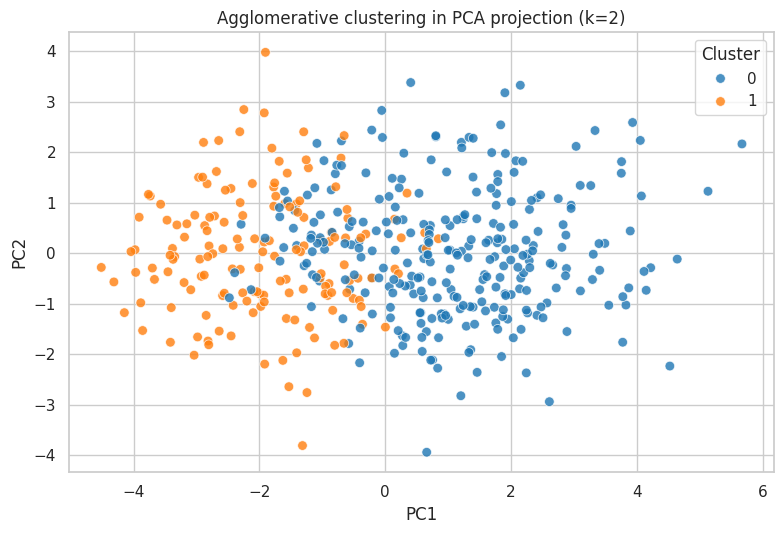

Agglomerative silhouette in full standardized feature space: 0.18


,cluster_size
0,285
1,157


In [ ]:
hier = AgglomerativeClustering(n_clusters=best_k, linkage="ward")
labels_hier = hier.fit_predict(X_scaled)
hier_viz = pd.DataFrame({"PC1": X_2d[:, 0], "PC2": X_2d[:, 1], "Cluster": labels_hier.astype(str)})
plt.figure(figsize=(8, 5.5))
sns.scatterplot(data=hier_viz, x="PC1", y="PC2", hue="Cluster", palette="tab10", s=48, alpha=.8)
plt.title(f"Agglomerative clustering in PCA projection (k={best_k})")
plt.tight_layout(); plt.show()
print("Agglomerative silhouette in full standardized feature space:", round(silhouette_score(X_scaled, labels_hier), 4))
display(pd.Series(labels_hier).value_counts().sort_index().rename("cluster_size").to_frame())

## 7. Compare methods

In [ ]:
def silhouette_or_nan(Xdata, labels):
    labels = np.asarray(labels)
    keep = labels != -1
    lab = labels[keep]
    if len(set(lab)) < 2 or len(set(lab)) >= len(lab):
        return np.nan
    return silhouette_score(Xdata[keep], lab)

comparison = pd.DataFrame([
    {"method": "K-Means", "clusters_excluding_noise": len(set(labels_kmeans)),
     "noise_fraction": 0.0, "silhouette": silhouette_or_nan(X_scaled, labels_kmeans)},
    {"method": "DBSCAN", "clusters_excluding_noise": len(set(labels_db)) - (1 if -1 in labels_db else 0),
     "noise_fraction": float(np.mean(labels_db == -1)), "silhouette": silhouette_or_nan(X_scaled, labels_db)},
    {"method": "Agglomerative", "clusters_excluding_noise": len(set(labels_hier)),
     "noise_fraction": 0.0, "silhouette": silhouette_or_nan(X_scaled, labels_hier)}
])
display(comparison.round(4))

,method,clusters_excluding_noise,noise_fraction,silhouette
0,K-Means,2,0.0000,0.2370
1,DBSCAN,2,0.1787,0.1788
2,Agglomerative,2,0.0000,0.1800


## 8. Findings and limitations

Use the plots and tables above to describe the actual results.

- **PCA** compresses ten features into fewer components. The scree and cumulative-variance plots show the trade-off between dimensionality and retained variance.
- **K-Means** creates compact groups but requires a chosen `k` and can be sensitive to outliers.
- **DBSCAN** can identify noise and dense regions, but the outcome depends strongly on `eps` and `min_samples`.
- **Agglomerative clustering** offers a hierarchical alternative; Ward linkage favors compact clusters.
- The 2D PCA plots are projections. Apparent overlap or separation in two dimensions may differ from structure in the full ten-dimensional feature space.
- Silhouette score is only one diagnostic; also consider cluster sizes, parameter sensitivity, and whether clusters are meaningful for the problem.
- This is exploratory clustering, not a validated clinical or predictive model.

### Conclusion template
Summarize (1) the number of PCs needed for 80% and 90% variance, (2) the candidate `k` suggested by silhouette and elbow plots, (3) DBSCAN's cluster/noise behavior, and (4) how cluster quality compares across methods.

## Reproducibility

Install dependencies:

```bash
pip install numpy pandas matplotlib seaborn scikit-learn jupyter
```

Open this notebook in Jupyter or VS Code and run all cells from top to bottom. All clustering is performed on standardized numerical features; the dataset target is excluded from model fitting.